# Assignment 9: Local Binary Patterns and Noise Removal

**Objective:**
1. Compute the Local Binary Pattern (LBP) texture descriptor of an image using the 8 neighbours of each pixel.
2. Add Gaussian and speckle noise, then compare four denoising filters: Wiener, Median, Gaussian and Bilateral.

> The input image is generated in code (no external image files needed). Settings that used to be typed in with `input()` are now variables at the top of each cell, so the notebook runs top to bottom without prompts.

In [1]:
from scipy.signal import wiener
import cv2
import numpy as np
import matplotlib.pyplot as plt


def create_demo_image(size=128, seed=42):
    """Build a grayscale test image (gradient + shapes + texture) with NumPy and OpenCV."""
    rng = np.random.default_rng(seed)

    # Smooth horizontal gradient as the background
    canvas = np.tile(np.linspace(40, 140, size, dtype=np.float32), (size, 1))

    # Bright square, dark circle and a mid-grey diagonal line give us edges and flat regions
    cv2.rectangle(canvas, (size // 8, size // 8), (size // 2, size // 2), 220, -1)
    cv2.circle(canvas, (int(size * 0.70), int(size * 0.65)), size // 5, 30, -1)
    cv2.line(canvas, (0, size - 1), (size - 1, size // 3), 180, 3)

    # Light texture so the image is not perfectly smooth
    canvas += rng.normal(0, 4, canvas.shape)
    return np.clip(canvas, 0, 255).astype(np.uint8)


def show_images(images, titles, columns=None, figsize=None):
    """Display several grayscale images side by side with titles."""
    columns = columns or len(images)
    rows = int(np.ceil(len(images) / columns))
    plt.figure(figsize=figsize or (4 * columns, 4 * rows))
    for index, (picture, title) in enumerate(zip(images, titles), start=1):
        plt.subplot(rows, columns, index)
        plt.imshow(picture, cmap="gray", vmin=0, vmax=255)
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

## Part A: Local Binary Pattern (LBP)
Each pixel is compared with its 8 neighbours (clockwise, starting at the top-left). A neighbour that is greater than or equal to the centre contributes a `1` bit; the 8 bits form the LBP code.

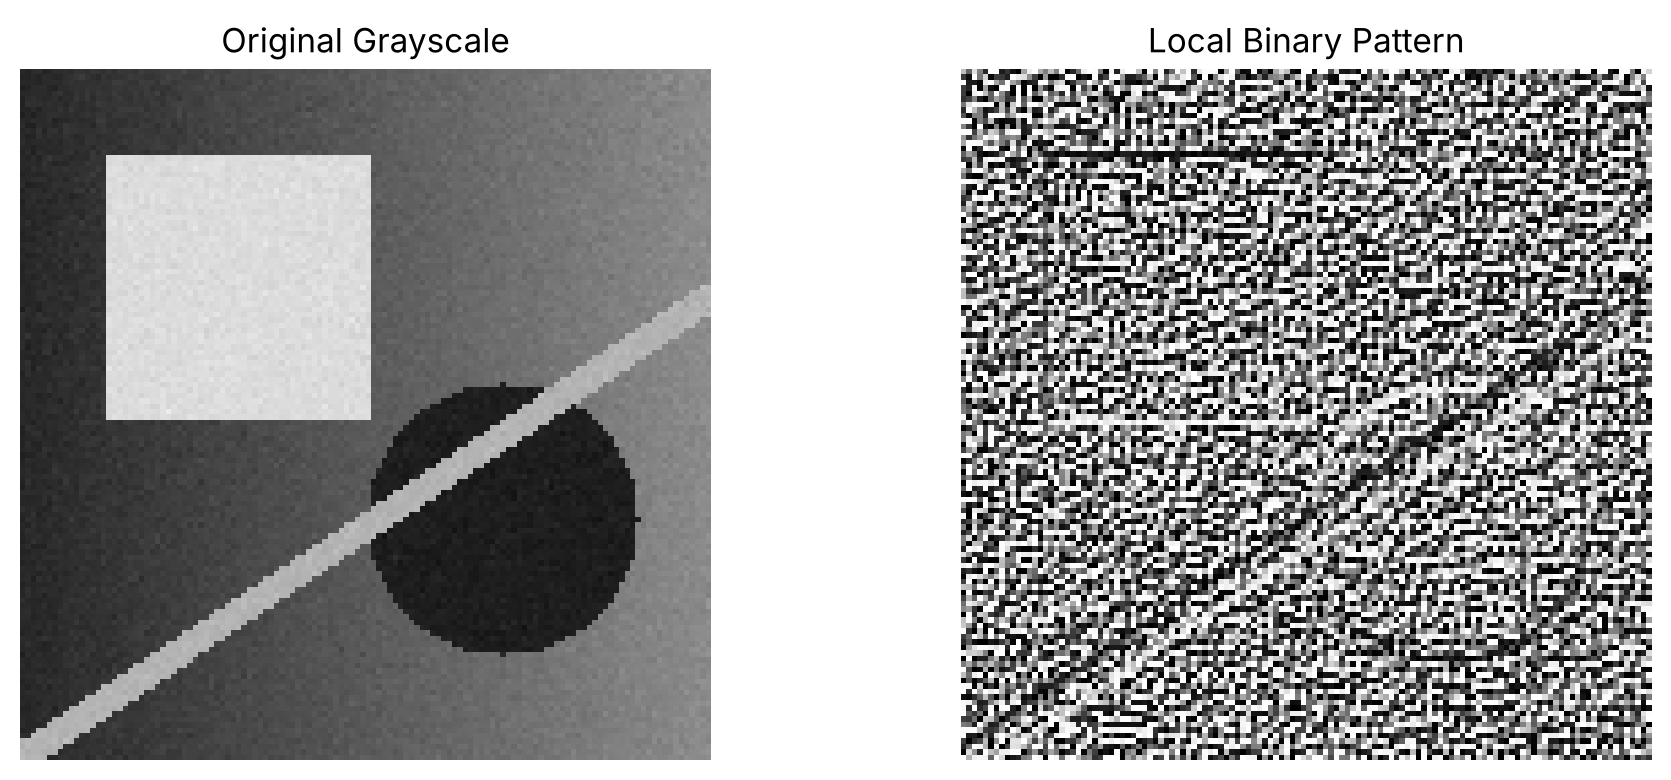

In [2]:
grayscale_image = create_demo_image()
height, width = grayscale_image.shape
lbp_image = np.zeros((height - 2, width - 2), dtype=np.uint8)

for row in range(1, height - 1):
    for col in range(1, width - 1):
        center = grayscale_image[row, col]
        code_value = 0
        code_value |= int(grayscale_image[row - 1, col - 1] >= center) << 7
        code_value |= int(grayscale_image[row - 1, col]     >= center) << 6
        code_value |= int(grayscale_image[row - 1, col + 1] >= center) << 5
        code_value |= int(grayscale_image[row,     col + 1] >= center) << 4
        code_value |= int(grayscale_image[row + 1, col + 1] >= center) << 3
        code_value |= int(grayscale_image[row + 1, col]     >= center) << 2
        code_value |= int(grayscale_image[row + 1, col - 1] >= center) << 1
        code_value |= int(grayscale_image[row,     col - 1] >= center) << 0
        lbp_image[row - 1, col - 1] = code_value

show_images([grayscale_image, lbp_image], ["Original Grayscale", "Local Binary Pattern"], figsize=(10, 4))

## Part B: Denoising Gaussian and speckle noise
A 5x5 window is used for all filters.

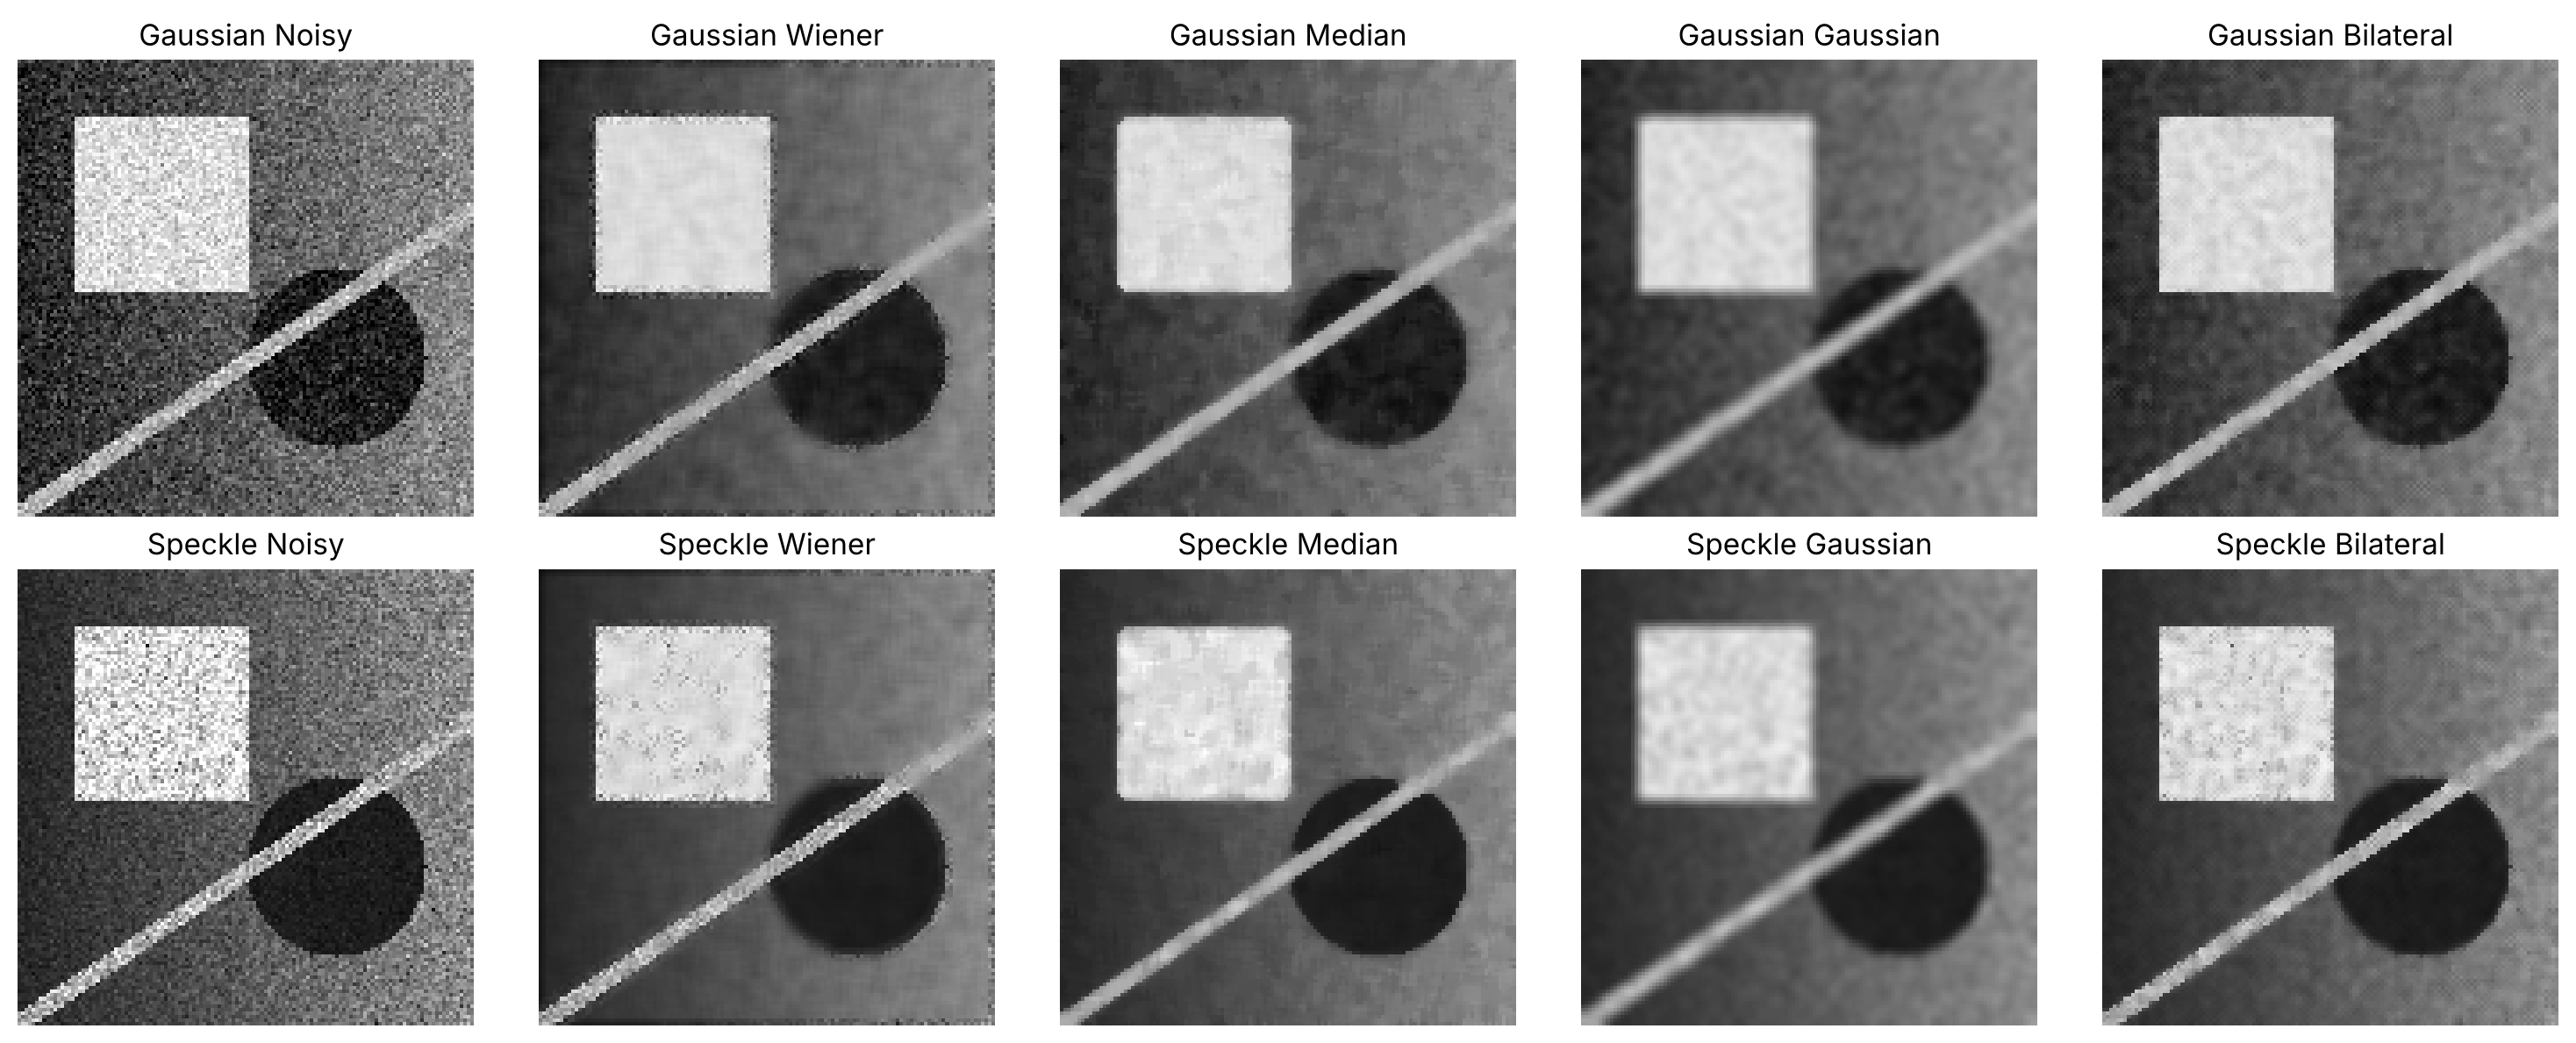

In [3]:
np.random.seed(0)   # reproducible noise

grayscale_image = create_demo_image()

gaussian_noise = np.random.normal(0, 25, grayscale_image.shape)
noisy_gaussian = np.clip(grayscale_image.astype(np.float32) + gaussian_noise, 0, 255).astype(np.uint8)

speckle_noise = np.random.normal(0, 0.2, grayscale_image.shape)
noisy_speckle = np.clip(grayscale_image.astype(np.float32) + grayscale_image * speckle_noise, 0, 255).astype(np.uint8)

WINDOW_SIZE = 5


def denoise_with_all_filters(noisy_image):
    """Return the Wiener, Median, Gaussian and Bilateral filtered versions of a noisy image."""
    wiener_result = np.clip(wiener(noisy_image.astype(np.float32), (WINDOW_SIZE, WINDOW_SIZE)), 0, 255).astype(np.uint8)
    median_result = cv2.medianBlur(noisy_image, WINDOW_SIZE)
    gaussian_result = cv2.GaussianBlur(noisy_image, (WINDOW_SIZE, WINDOW_SIZE), 1.5)
    bilateral_result = cv2.bilateralFilter(noisy_image, WINDOW_SIZE, 75, 75)
    return wiener_result, median_result, gaussian_result, bilateral_result


wiener_g, median_g, gaussian_g, bilateral_g = denoise_with_all_filters(noisy_gaussian)
wiener_s, median_s, gaussian_s, bilateral_s = denoise_with_all_filters(noisy_speckle)

panel_titles = ["Noisy", "Wiener", "Median", "Gaussian", "Bilateral"]

plt.figure(figsize=(15, 6))
for index, panel in enumerate([noisy_gaussian, wiener_g, median_g, gaussian_g, bilateral_g]):
    plt.subplot(2, 5, index + 1)
    plt.imshow(panel, cmap="gray", vmin=0, vmax=255)
    plt.title("Gaussian " + panel_titles[index])
    plt.axis("off")

for index, panel in enumerate([noisy_speckle, wiener_s, median_s, gaussian_s, bilateral_s]):
    plt.subplot(2, 5, index + 6)
    plt.imshow(panel, cmap="gray", vmin=0, vmax=255)
    plt.title("Speckle " + panel_titles[index])
    plt.axis("off")

plt.tight_layout()
plt.show()